# RetailPulse — Day 04: Customer Churn & Inactivity Risk Analysis
## AI-Powered Customer Analytics & Demand Forecasting Platform

### Objective
This notebook formulates and evaluates a defensible customer churn prediction framework using historical transaction data from **Online Retail II**.

### Key Methodological Requirements
1. **Observation Cutoff Date:** Fixed at **2011-09-01** (90 days before the final ledger date).
2. **Historical Feature Window:** All qualifying transactions occurring strictly prior to 2011-09-01.
3. **Outcome Horizon:** The 90-day window from 2011-09-01 to 2011-12-09.
4. **Target Formulation:** A customer is labeled as **Churned ($y=1$)** if they recorded zero qualifying transactions during the 90-day forward outcome window, and **Active ($y=0$)** if they made at least one purchase.
5. **No Data Leakage:** Predictive features are calculated strictly using data available on or before the cutoff date.
6. **Model Benchmarking:** Baseline **Logistic Regression** vs non-linear **Random Forest Classifier** evaluated using Precision, Recall, F1-Score, ROC-AUC, and PR-AUC.

In [1]:
import sys
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Add project root to sys.path
root_dir = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(root_dir))

from src import config
from src.churn import build_churn_dataset, train_and_evaluate_churn_models, compute_inactivity_risk_tiers
print("RetailPulse environment and libraries initialized successfully!")

RetailPulse environment and libraries initialized successfully!


## Step 1: Load Cleaned Transactions & Formulate Churn Dataset
We load the preprocessed transaction records from `data/processed/cleaned_transactions.parquet` and apply the leakage-free windowing logic.

In [2]:
df_cleaned = pd.read_parquet(root_dir / config.CLEANED_TRANSACTIONS_PARQUET)
print(f"Total cleaned transactions loaded: {len(df_cleaned):,}")

# Build time-windowed churn dataset
df_churn, meta = build_churn_dataset(df_cleaned, cutoff_date=pd.Timestamp("2011-09-01"))
print("\n--- Churn Problem Formulation Metadata ---")
for k, v in meta.items():
    print(f"  {k:22}: {v}")

display(df_churn.head(10))

Total cleaned transactions loaded: 1,055,238



--- Churn Problem Formulation Metadata ---
  cutoff_date           : 2011-09-01
  outcome_window_days   : 90
  eligible_customers    : 5249
  churned_count         : 2905
  active_count          : 2344
  churn_rate_pct        : 55.34


,Customer ID,Last_Purchase,First_Purchase,Frequency,Monetary,Total_Units,Recency,Tenure_Days,Avg_Order_Value,Recent_30D_Spend,Recent_30D_Tx,Churned
0,12346,2011-01-18 10:01:00,2009-12-14 08:34:00,12,77556.46,74285,226,626,6463.04,0.00,0.0,1
1,12347,2011-08-02 08:48:00,2010-10-31 14:20:00,6,4114.18,2418,30,305,685.70,584.91,1.0,0
2,12348,2011-04-05 10:47:00,2010-09-27 14:59:00,4,1709.40,2497,149,339,427.35,0.00,0.0,0
3,12349,2010-10-28 08:23:00,2010-04-29 13:20:00,3,2671.14,993,308,490,890.38,0.00,0.0,0
4,12350,2011-02-02 16:01:00,2011-02-02 16:01:00,1,334.40,197,211,211,334.40,0.00,0.0,1
5,12351,2010-11-29 15:23:00,2010-11-29 15:23:00,1,300.93,261,276,276,300.93,0.00,0.0,1
6,12352,2011-03-22 16:08:00,2010-11-12 10:20:00,7,1905.61,442,163,293,272.23,0.00,0.0,0
7,12353,2011-05-19 17:47:00,2010-10-27 12:44:00,2,406.76,212,105,309,203.38,0.00,0.0,1
8,12354,2011-04-21 13:11:00,2011-04-21 13:11:00,1,1079.40,530,133,133,1079.40,0.00,0.0,1
9,12355,2011-05-09 13:49:00,2010-05-21 11:59:00,2,947.61,543,115,468,473.80,0.00,0.0,1


## Step 2: Class Balance & Feature Distributions
Inspect target class distributions and key predictive features (Recency, Frequency, Monetary, Tenure, Recent 30D spend).

C:\Users\shubhAM\AppData\Local\Temp\ipykernel_4872\304295163.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_churn, x="Churned", y="Recency", palette=["#2ca02c", "#d62728"], ax=axes[1])
C:\Users\shubhAM\AppData\Local\Temp\ipykernel_4872\304295163.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1].set_xticklabels(["Active", "Churned"])


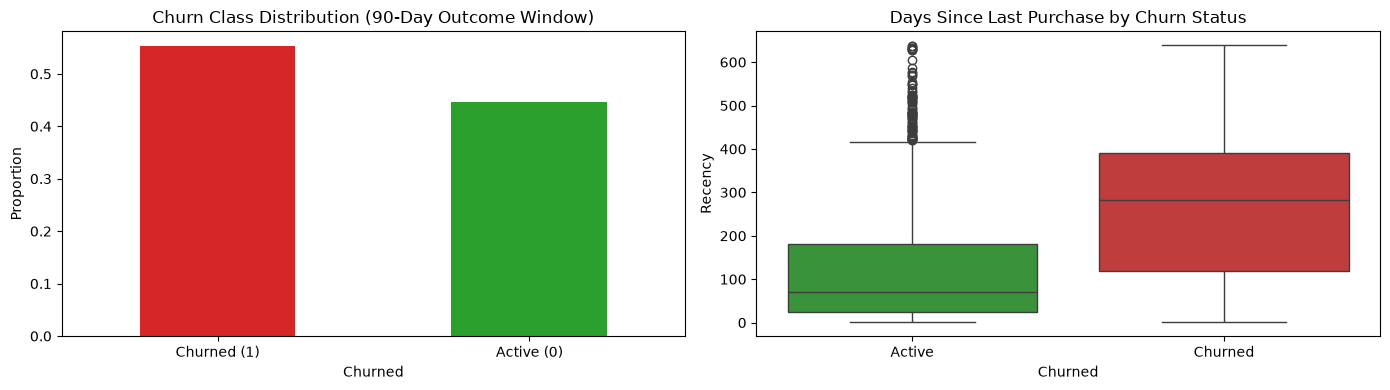

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Churn Distribution
df_churn["Churned"].value_counts(normalize=True).plot(
    kind="bar",
    color=["#d62728", "#2ca02c"],
    ax=axes[0],
    title="Churn Class Distribution (90-Day Outcome Window)"
)
axes[0].set_xticklabels(["Churned (1)", "Active (0)"], rotation=0)
axes[0].set_ylabel("Proportion")

# Recency vs Churn
sns.boxplot(data=df_churn, x="Churned", y="Recency", palette=["#2ca02c", "#d62728"], ax=axes[1])
axes[1].set_xticklabels(["Active", "Churned"])
axes[1].set_title("Days Since Last Purchase by Churn Status")

plt.tight_layout()
plt.show()

## Step 3: Model Training & Evaluation (Logistic Regression vs Random Forest)
We evaluate both models using a stratified 80/20 train/test split.

In [4]:
eval_results = train_and_evaluate_churn_models(df_churn, export=True)

lr_metrics = eval_results["baseline_logistic_regression"]
rf_metrics = eval_results["random_forest"]

comp_df = pd.DataFrame([
    {"Model": "Logistic Regression (Baseline)", **lr_metrics},
    {"Model": "Random Forest (Nonlinear)", **rf_metrics}
])
display(comp_df[["Model", "Precision", "Recall", "F1_Score", "ROC_AUC", "PR_AUC"]])

[Churn] Exported churn model and metrics to C:\Users\shubhAM\Desktop\RetailPulse_ZIDIO_INTERNSHIP\models\churn


,Model,Precision,Recall,F1_Score,ROC_AUC,PR_AUC
0,Logistic Regression (Baseline),0.7355,0.7849,0.7594,0.8094,0.8262
1,Random Forest (Nonlinear),0.7532,0.8193,0.7848,0.8211,0.8283


## Step 4: Feature Importance Analysis
Which behavioral signals most strongly predict future churn?

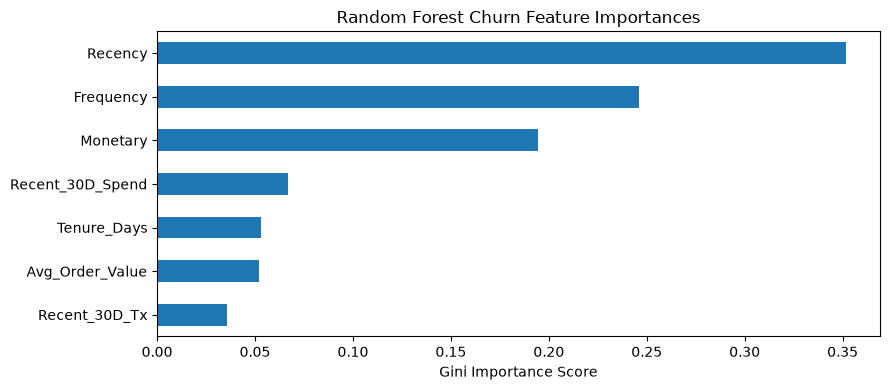

In [5]:
feat_imp = pd.Series(eval_results["feature_importances"]).sort_values(ascending=True)
plt.figure(figsize=(9, 4))
feat_imp.plot(kind="barh", color="#1f77b4")
plt.title("Random Forest Churn Feature Importances")
plt.xlabel("Gini Importance Score")
plt.tight_layout()
plt.show()

## Step 5: Operational Inactivity Risk Tiers
In addition to the supervised model, we construct transparent, rule-based recency tiers for day-to-day operational account management.

In [6]:
df_rfm = pd.read_parquet(root_dir / config.RFM_CUSTOMERS_PARQUET)
df_tiers = compute_inactivity_risk_tiers(df_rfm)

tier_summary = df_tiers["Inactivity_Risk_Tier"].value_counts().reset_index()
tier_summary.columns = ["Inactivity Risk Tier", "Customer Count"]
tier_summary["Percentage"] = (tier_summary["Customer Count"] / len(df_tiers) * 100).round(1)
display(tier_summary)
print("Notebook Day 04 execution completed successfully!")

,Inactivity Risk Tier,Customer Count,Percentage
0,Active / Very Recent,1628,27.7
1,Dormant (> 1 year),1614,27.5
2,Stable / Moderate Recency,1261,21.5
3,High Inactivity (180-365 days),787,13.4
4,Inactivity Risk (90-180 days),588,10.0


Notebook Day 04 execution completed successfully!
